# TA-07 — Implementasi Q-Learning untuk Skenario RL Diskrit
**Mata Praktikum:** Pembelajaran Mesin · **Modul 07:** Reinforcement Learning (Q-Learning)
**Nama:** windi nuralika repani · **NIM:** 301240009

**Skenario (dari TP-07):** *Agen Kurir Otomatis Pengantar Paket pada Grid Kota Mini 5×5 dengan Manajemen Baterai.*

Notebook ini berisi seluruh langkah TA-07, dengan lingkungan dibangun dari nol memakai Python murni (tanpa Gymnasium):

| Langkah | Isi |
|---|---|
| 1 | Persiapan lingkungan (kelas `CourierEnv`, re-definisi S, A, R) |
| 2 | Implementasi Q-Learning + ε-greedy dengan peluruhan |
| 3 | Rekam reward per episode, kurva pembelajaran (moving average, window 100), analisis konvergensi |
| 4 | Ekstraksi kebijakan optimal, visualisasi grid berpanah, interpretasi logis |
| 5 | Eksperimen hiperparameter (γ default tinggi vs. γ sangat rendah) |


## Langkah 1 — Persiapan Lingkungan

### Re-definisi S, A, R (lanjutan dari TP-07)

| Elemen | Definisi |
|---|---|
| **Agent** | Robot kurir otonom yang memilih satu aksi pada setiap langkah waktu. |
| **Environment** | Grid 5×5 (25 sel) dengan 3 sel penghalang → 22 sel bebas. Satu titik pengambilan **P** `(0,0)`, empat tujuan **T1 (4,0), T2 (4,2), T3 (4,4), T4 (0,4)**, satu stasiun pengisian daya **C** `(2,2)`, penghalang di `(1,1)`, `(3,1)`, `(3,3)`. |
| **State (S)** | Tuple `(x, y, tujuan, status_paket, baterai)` → 25 × 4 × 2 × 3 = **600 state** (528 state efektif setelah penghalang dikeluarkan). Baterai: 0 = Rendah, 1 = Sedang, 2 = Tinggi. |
| **Action (A)** | 6 aksi: 0 Atas, 1 Bawah, 2 Kiri, 3 Kanan, 4 Angkut/Serahkan, 5 Isi daya. |
| **Reward (R)** | −1 setiap langkah (selalu berlaku), **ditambah**: −3 menabrak tembok/penghalang · +5 berhasil mengambil paket di P · +30 paket diserahkan di tujuan yang benar (terminal) · −10 Angkut/Serahkan di tempat yang salah · −2 Isi daya di luar C · +2 Isi daya di C saat baterai Rendah/Sedang · −50 baterai habis sebelum paket terantar (terminal). |
| **Dinamika stokastik** | Setiap gerakan menurunkan baterai satu tingkat dengan peluang 0,2. Jika baterai sudah Rendah dan turun lagi → baterai habis (terminal). |
| **Episode** | Mulai di sel acak, paket belum diambil, tujuan acak (T1–T4), baterai Tinggi. Berakhir bila paket terantar, baterai habis, atau 100 langkah. |

**Catatan implementasi (klarifikasi dari TP-07):**
- Biaya −1 per langkah dijumlahkan dengan komponen reward lain (mis. mengambil paket = −1 + 5 = **+4**, mengantar = −1 + 30 = **+29**).
- Isi daya di C saat baterai sudah Tinggi: tidak ada perubahan baterai, hanya biaya langkah −1.
- Di state terminal, target Bellman = reward saja (tanpa suku γ·maxQ).
- Ukuran Q-Table: 600 × 6 = **3.600 sel**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

SEED = 42
EPISODES = 20000
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
print("NumPy", np.__version__, "| Pandas", pd.__version__)

NumPy 2.5.4 | Pandas 3.0.6


### Kelas lingkungan simulasi
Fungsi `step(state, action)` menerima state & action, lalu mengembalikan `(new_state, reward, done)` sesuai spesifikasi tugas.

In [2]:
class CourierEnv:
    """Lingkungan Kurir Otomatis pada grid kota mini 5x5 (skenario TP-07).

    State  : tuple (x, y, tujuan, status_paket, baterai)
             x, y        -> posisi agen (kolom, baris), 0..4
             tujuan      -> 0..3 (T1..T4)
             status_paket-> 0 = belum diambil, 1 = sedang dibawa
             baterai     -> 0 = Rendah, 1 = Sedang, 2 = Tinggi
    Action : 0 Atas, 1 Bawah, 2 Kiri, 3 Kanan, 4 Angkut/Serahkan, 5 Isi daya
    """
    GRID = 5
    WALLS = {(1, 1), (3, 1), (3, 3)}              # 3 sel penghalang (bangunan)
    PICKUP = (0, 0)                               # P
    DESTS = [(4, 0), (4, 2), (4, 4), (0, 4)]      # T1, T2, T3, T4
    CHARGER = (2, 2)                              # C
    ACTION_NAMES = ["Atas", "Bawah", "Kiri", "Kanan", "Angkut/Serahkan", "Isi daya"]
    MOVES = {0: (0, -1), 1: (0, 1), 2: (-1, 0), 3: (1, 0)}   # (dx, dy); baris 0 di atas

    N_POS, N_DEST, N_CARRY, N_BATT = 25, 4, 2, 3
    N_STATES = N_POS * N_DEST * N_CARRY * N_BATT   # 600
    N_ACTIONS = 6

    P_BATT_DROP = 0.2    # peluang baterai turun satu tingkat setiap gerakan
    MAX_STEPS = 100      # batas langkah per episode

    def __init__(self, seed=None):
        self.rng = np.random.default_rng(seed)
        self.free_cells = [(x, y) for y in range(self.GRID) for x in range(self.GRID)
                           if (x, y) not in self.WALLS]          # 22 sel

    # ---------- encode / decode state <-> indeks Q-Table ----------
    def encode(self, state):
        x, y, d, c, b = state
        return (((y * self.GRID + x) * self.N_DEST + d) * self.N_CARRY + c) * self.N_BATT + b

    def decode(self, idx):
        idx, b = divmod(idx, self.N_BATT)
        idx, c = divmod(idx, self.N_CARRY)
        idx, d = divmod(idx, self.N_DEST)
        y, x = divmod(idx, self.GRID)
        return (x, y, d, c, b)

    # ---------- reset ----------
    def reset(self):
        """Posisi acak, paket belum diambil, tujuan acak, baterai Tinggi."""
        x, y = self.free_cells[self.rng.integers(len(self.free_cells))]
        d = int(self.rng.integers(self.N_DEST))
        return (x, y, d, 0, 2)

    # ---------- dinamika lingkungan ----------
    def step(self, state, action):
        """Menerima (state, action) -> mengembalikan (new_state, reward, done).
        Reward = -1 (biaya langkah, selalu) + komponen kejadian di bawah ini."""
        x, y, d, c, b = state
        reward, done = -1.0, False

        if action in self.MOVES:                                   # bergerak
            dx, dy = self.MOVES[action]
            nx, ny = x + dx, y + dy
            if not (0 <= nx < self.GRID and 0 <= ny < self.GRID) or (nx, ny) in self.WALLS:
                reward += -3.0                                     # menabrak tembok/penghalang
                nx, ny = x, y                                      # tetap di tempat
            x, y = nx, ny
            if self.rng.random() < self.P_BATT_DROP:               # baterai turun (stokastik)
                if b == 0:
                    reward += -50.0                                # baterai habis (terminal)
                    done = True
                else:
                    b -= 1

        elif action == 4:                                          # angkut / serahkan
            if c == 0 and (x, y) == self.PICKUP:
                c = 1
                reward += 5.0                                      # berhasil mengambil paket
            elif c == 1 and (x, y) == self.DESTS[d]:
                reward += 30.0                                     # paket terantar (terminal)
                done = True
            else:
                reward += -10.0                                    # aksi di tempat yang salah

        elif action == 5:                                          # isi daya
            if (x, y) == self.CHARGER:
                if b < 2:
                    b += 1
                    reward += 2.0                                  # mengisi saat Rendah/Sedang
            else:
                reward += -2.0                                     # isi daya di luar stasiun

        return (x, y, d, c, b), reward, done


env = CourierEnv(seed=SEED)
print("Jumlah sel bebas        :", len(env.free_cells))
print("Total state (maks)      :", env.N_STATES, "| state efektif (22 sel):", 22 * 4 * 2 * 3)
print("Jumlah aksi             :", env.N_ACTIONS)
print("Ukuran Q-Table          :", (env.N_STATES, env.N_ACTIONS), "=", env.N_STATES * env.N_ACTIONS, "sel")

# Uji encode/decode dan satu langkah simulasi
s = env.reset()
print("\nState awal contoh        :", s, "-> indeks", env.encode(s), "-> decode", env.decode(env.encode(s)))
print("Hasil step(Kanan)        :", env.step(s, 3))

Jumlah sel bebas        : 22
Total state (maks)      : 600 | state efektif (22 sel): 528
Jumlah aksi             : 6
Ukuran Q-Table          : (600, 6) = 3600 sel

State awal contoh        : (1, 0, 3, 0, 2) -> indeks 44 -> decode (1, 0, 3, 0, 2)
Hasil step(Kanan)        : ((2, 0, 3, 0, 2), -1.0, False)


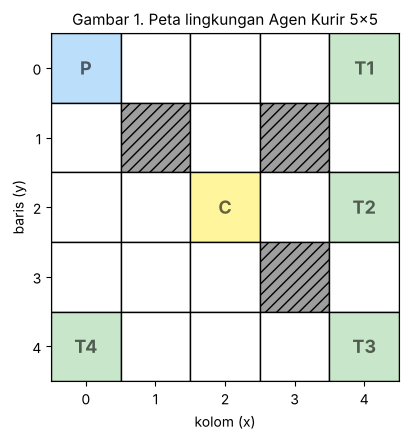

In [3]:
def draw_map(ax, title="Peta Lingkungan"):
    """Gambar dasar grid: P, T1-T4, C, dan penghalang."""
    n = CourierEnv.GRID
    for y in range(n):
        for x in range(n):
            color, label = "white", ""
            if (x, y) in CourierEnv.WALLS:
                color = "#9e9e9e"
            elif (x, y) == CourierEnv.PICKUP:
                color, label = "#bbdefb", "P"
            elif (x, y) == CourierEnv.CHARGER:
                color, label = "#fff59d", "C"
            elif (x, y) in CourierEnv.DESTS:
                color, label = "#c8e6c9", f"T{CourierEnv.DESTS.index((x, y)) + 1}"
            ax.add_patch(Rectangle((x - .5, y - .5), 1, 1, facecolor=color, edgecolor="black", lw=1,
                                   hatch="///" if (x, y) in CourierEnv.WALLS else None))
            if label:
                ax.text(x, y, label, ha="center", va="center", fontsize=13, fontweight="bold", alpha=.6)
    ax.set_xlim(-.5, n - .5); ax.set_ylim(n - .5, -.5)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xlabel("kolom (x)"); ax.set_ylabel("baris (y)")
    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_map(ax, "Gambar 1. Peta lingkungan Agen Kurir 5×5")
plt.tight_layout(); plt.show()

## Langkah 2 — Implementasi Q-Learning

- **Q-Table** `Q[|S|×|A|]` diinisialisasi **nol**.
- **Persamaan Bellman:** $Q(s,a) \leftarrow (1-\alpha)\,Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a')\,]$
- **ε-greedy** dengan peluruhan eksponensial: $\epsilon = \epsilon_{min} + (\epsilon_{start}-\epsilon_{min})\,e^{-\text{decay}\cdot episode}$, dari 1,0 menuju 0,05 (ε sudah ≈ 0,05 pada episode ~5.000).
- **Hiperparameter dasar** (sesuai rencana di TP-07): α = 0,1 · γ = 0,95 · decay = 0,001.
- **Jumlah episode = 20.000.** Karena α = 0,1 cukup kecil dan lingkungannya stokastik, 8.000 episode belum cukup untuk melihat plateau yang stabil.
- Pada pemilihan aksi greedy, seri nilai Q dipecah secara acak agar agen tidak selalu condong ke aksi 0 saat Q-Table masih nol.


In [4]:
def greedy_action(q_row, rng):
    """argmax dengan pemecah seri acak (agar tidak bias ke aksi 0 saat nilai Q masih sama)."""
    best = np.flatnonzero(q_row == q_row.max())
    return int(rng.choice(best))


def train_q_learning(alpha=0.1, gamma=0.95, episodes=EPISODES,
                     eps_start=1.0, eps_min=0.05, decay_rate=0.001,
                     max_steps=100, seed=SEED, verbose=True):
    """Pelatihan Q-Learning tabular.
    Q(s,a) <- (1-alpha) Q(s,a) + alpha [ r + gamma * max_a' Q(s',a') ]   (tanpa bootstrap di state terminal)
    Epsilon meluruh eksponensial: eps = eps_min + (eps_start - eps_min) * exp(-decay_rate * episode)
    """
    env = CourierEnv(seed=seed)
    rng = np.random.default_rng(seed + 1)          # RNG untuk keputusan epsilon-greedy
    Q = np.zeros((env.N_STATES, env.N_ACTIONS))    # inisialisasi nol
    visits = np.zeros(env.N_STATES, dtype=int)

    rewards_per_ep, success_per_ep, steps_per_ep, eps_per_ep = [], [], [], []
    epsilon = eps_start

    for ep in range(episodes):
        state = env.reset()
        total_reward, success = 0.0, 0

        for t in range(max_steps):
            s = env.encode(state)
            visits[s] += 1

            # 1. Pilih aksi: epsilon-greedy
            if rng.random() < epsilon:
                action = int(rng.integers(env.N_ACTIONS))      # eksplorasi
            else:
                action = greedy_action(Q[s], rng)              # eksploitasi

            # 2. Jalankan aksi
            new_state, reward, done = env.step(state, action)
            s2 = env.encode(new_state)

            # 3. Perbarui Q-Table (Persamaan Bellman)
            target = reward + (0.0 if done else gamma * Q[s2].max())
            Q[s, action] = (1 - alpha) * Q[s, action] + alpha * target

            total_reward += reward
            state = new_state
            if done:
                success = int(reward > 0)      # done dengan reward positif = paket terantar
                break

        # 4. Peluruhan epsilon
        epsilon = eps_min + (eps_start - eps_min) * np.exp(-decay_rate * ep)

        rewards_per_ep.append(total_reward)
        success_per_ep.append(success)
        steps_per_ep.append(t + 1)
        eps_per_ep.append(epsilon)

        if verbose and (ep + 1) % 2000 == 0:
            print(f"Episode {ep+1:>5} | eps={epsilon:.3f} | rata2 reward (100 terakhir)="
                  f"{np.mean(rewards_per_ep[-100:]):7.2f} | sukses (100 terakhir)={np.mean(success_per_ep[-100:]):.2f}")

    return dict(Q=Q, visits=visits, rewards=np.array(rewards_per_ep), success=np.array(success_per_ep),
                steps=np.array(steps_per_ep), eps=np.array(eps_per_ep),
                params=dict(alpha=alpha, gamma=gamma, episodes=episodes, eps_start=eps_start,
                            eps_min=eps_min, decay_rate=decay_rate))


# ---- Pelatihan dasar (hiperparameter dari rencana TP-07) ----
base = train_q_learning(alpha=0.1, gamma=0.95, episodes=EPISODES,
                        eps_start=1.0, eps_min=0.05, decay_rate=0.001)
Q_base = base["Q"]
print("\nBentuk Q-Table:", Q_base.shape)
print("State yang pernah dikunjungi:", int((base["visits"] > 0).sum()), "dari", CourierEnv.N_STATES)

Episode  2000 | eps=0.179 | rata2 reward (100 terakhir)= -43.81 | sukses (100 terakhir)=0.49
Episode  4000 | eps=0.067 | rata2 reward (100 terakhir)=  -6.81 | sukses (100 terakhir)=0.76
Episode  6000 | eps=0.052 | rata2 reward (100 terakhir)=   3.75 | sukses (100 terakhir)=0.83
Episode  8000 | eps=0.050 | rata2 reward (100 terakhir)=  14.04 | sukses (100 terakhir)=0.92
Episode 10000 | eps=0.050 | rata2 reward (100 terakhir)=   3.85 | sukses (100 terakhir)=0.81
Episode 12000 | eps=0.050 | rata2 reward (100 terakhir)=  10.47 | sukses (100 terakhir)=0.88
Episode 14000 | eps=0.050 | rata2 reward (100 terakhir)=   9.74 | sukses (100 terakhir)=0.86
Episode 16000 | eps=0.050 | rata2 reward (100 terakhir)=   8.05 | sukses (100 terakhir)=0.84
Episode 18000 | eps=0.050 | rata2 reward (100 terakhir)=  13.08 | sukses (100 terakhir)=0.90
Episode 20000 | eps=0.050 | rata2 reward (100 terakhir)=  12.78 | sukses (100 terakhir)=0.91

Bentuk Q-Table: (600, 6)
State yang pernah dikunjungi: 528 dari 600


## Langkah 3 — Analisis Konvergensi dan Eksplorasi
Total reward tiap episode dicatat selama pelatihan, lalu dihaluskan dengan *moving average* (window = 100).

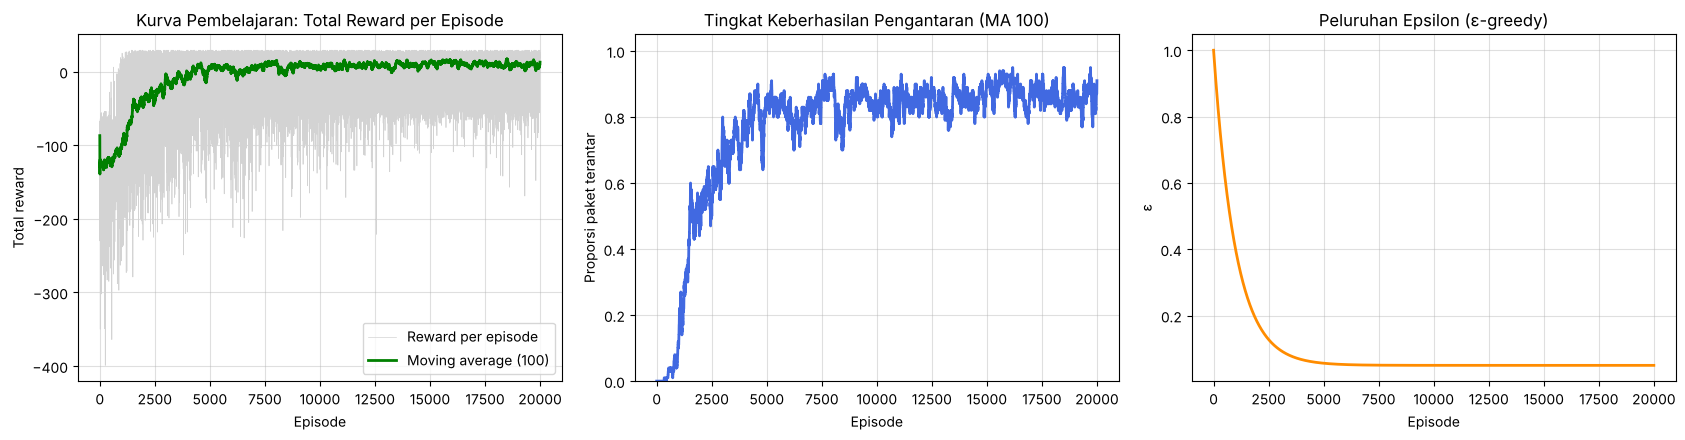

In [5]:
def moving_average(x, window=100):
    return pd.Series(x).rolling(window=window, min_periods=1).mean().values

WINDOW = 100
ma_reward = moving_average(base["rewards"], WINDOW)
ma_success = moving_average(base["success"], WINDOW)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(base["rewards"], color="lightgray", lw=.5, label="Reward per episode")
axes[0].plot(ma_reward, color="green", lw=2, label=f"Moving average ({WINDOW})")
axes[0].set_title("Kurva Pembelajaran: Total Reward per Episode")
axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Total reward"); axes[0].legend(); axes[0].grid(True, alpha=.4)

axes[1].plot(ma_success, color="royalblue", lw=2)
axes[1].set_title(f"Tingkat Keberhasilan Pengantaran (MA {WINDOW})")
axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Proporsi paket terantar"); axes[1].set_ylim(0, 1.05); axes[1].grid(True, alpha=.4)

axes[2].plot(base["eps"], color="darkorange", lw=2)
axes[2].set_title("Peluruhan Epsilon (ε-greedy)")
axes[2].set_xlabel("Episode"); axes[2].set_ylabel("ε"); axes[2].grid(True, alpha=.4)

plt.tight_layout(); plt.show()

In [6]:
def convergence_episode(x, window=500, tail=2000, tol_frac=0.05):
    """Episode pertama setelah mana moving average (window=500) tidak lagi keluar dari pita ±tol di sekitar plateau.
    Plateau = rata-rata `tail` episode terakhir; tol = tol_frac x |plateau - rata-rata 200 episode pertama|."""
    ma = pd.Series(x).rolling(window, min_periods=window).mean().values
    plateau = np.mean(x[-tail:])
    tol = tol_frac * abs(plateau - np.mean(x[:200]))
    valid = ~np.isnan(ma)
    outside = np.flatnonzero(valid & (np.abs(ma - plateau) > tol))
    ep = int(outside[-1]) + 1 if len(outside) else window
    return ep, plateau, tol

conv_r, plat_r, tol_r = convergence_episode(base["rewards"])
conv_s, plat_s, tol_s = convergence_episode(base["success"])

print(f"Reward rata-rata 200 episode pertama : {base['rewards'][:200].mean():8.2f}  (std = {base['rewards'][:200].std():.2f})")
print(f"Reward rata-rata 2000 episode akhir  : {plat_r:8.2f}  (std = {base['rewards'][-2000:].std():.2f})")
print(f"Konvergensi reward (MA-500 dalam ±{tol_r:.1f} dari plateau)  : episode ke-{conv_r}")
print(f"Tingkat sukses 200 episode pertama   : {base['success'][:200].mean():.1%}")
print(f"Tingkat sukses 2000 episode akhir    : {plat_s:.1%}")
print(f"Konvergensi sukses (MA-500 dalam ±{tol_s:.3f} dari plateau): episode ke-{conv_s}")
print(f"Epsilon pada episode konvergensi     : {base['eps'][conv_r]:.3f}")

Reward rata-rata 200 episode pertama :  -125.77  (std = 52.49)
Reward rata-rata 2000 episode akhir  :     8.74  (std = 30.14)
Konvergensi reward (MA-500 dalam ±6.7 dari plateau)  : episode ke-8617
Tingkat sukses 200 episode pertama   : 0.0%
Tingkat sukses 2000 episode akhir    : 85.7%
Konvergensi sukses (MA-500 dalam ±0.043 dari plateau): episode ke-16231
Epsilon pada episode konvergensi     : 0.050


### Analisis Kurva Pembelajaran

**Apa yang ditunjukkan plot?** Kurva rata-rata reward naik dari sekitar **−126** (200 episode pertama) menjadi sekitar **+9** (2.000 episode terakhir), sedangkan tingkat keberhasilan pengantaran naik dari **0 %** menjadi sekitar **86 %**.

**Pada episode berapa konvergen?** Dengan kriteria *moving average* 500 episode tidak lagi keluar dari pita ±5 % dari selisih awal–akhir di sekitar plateau, reward **konvergen sekitar episode ke-8.600**. Kenaikan tercuram terjadi pada episode ± 1.000–5.000, bersamaan dengan turunnya ε dari 1,0 ke ≈ 0,07. Tingkat keberhasilan masih berfluktuasi di kisaran 75–95 % setelah itu (kriteria yang jauh lebih ketat memberi angka ±16.000, tetapi itu hanya mencerminkan noise).

**Fluktuasi di awal pelatihan.** Pada awal pelatihan ε ≈ 1, sehingga agen hampir sepenuhnya bergerak acak: sering menabrak tembok (−3), salah mengangkut/menyerahkan (−10), dan kehabisan baterai (−50). Reward per episode menjadi sangat negatif dan sangat bervariasi (std ≈ 52 pada 200 episode pertama; titik terendah mendekati −400). Q-Table masih hampir nol, sehingga +5 dan +30 baru ditemukan secara kebetulan.

**Mengapa plateau tidak mencapai 100 %?** (1) Masih ada eksplorasi acak ε = 0,05 selama pelatihan; (2) baterai turun secara stokastik (p = 0,2 per gerakan; rata-rata baterai bertahan ± 15 gerakan), sehingga pada start yang jauh baterai bisa habis meski kebijakannya baik. Nilai plateau ini adalah performa selama pelatihan (dengan eksplorasi); performa kebijakan greedy murni diukur di Langkah 4.


## Langkah 4 — Analisis dan Interpretasi Kebijakan (Policy)
Kebijakan optimal diekstrak dengan $\pi(s)=\arg\max_a Q(s,a)$. Karena state memiliki 5 dimensi, kebijakan digambar per *konteks* (status paket, tujuan, baterai) pada grid 5×5.

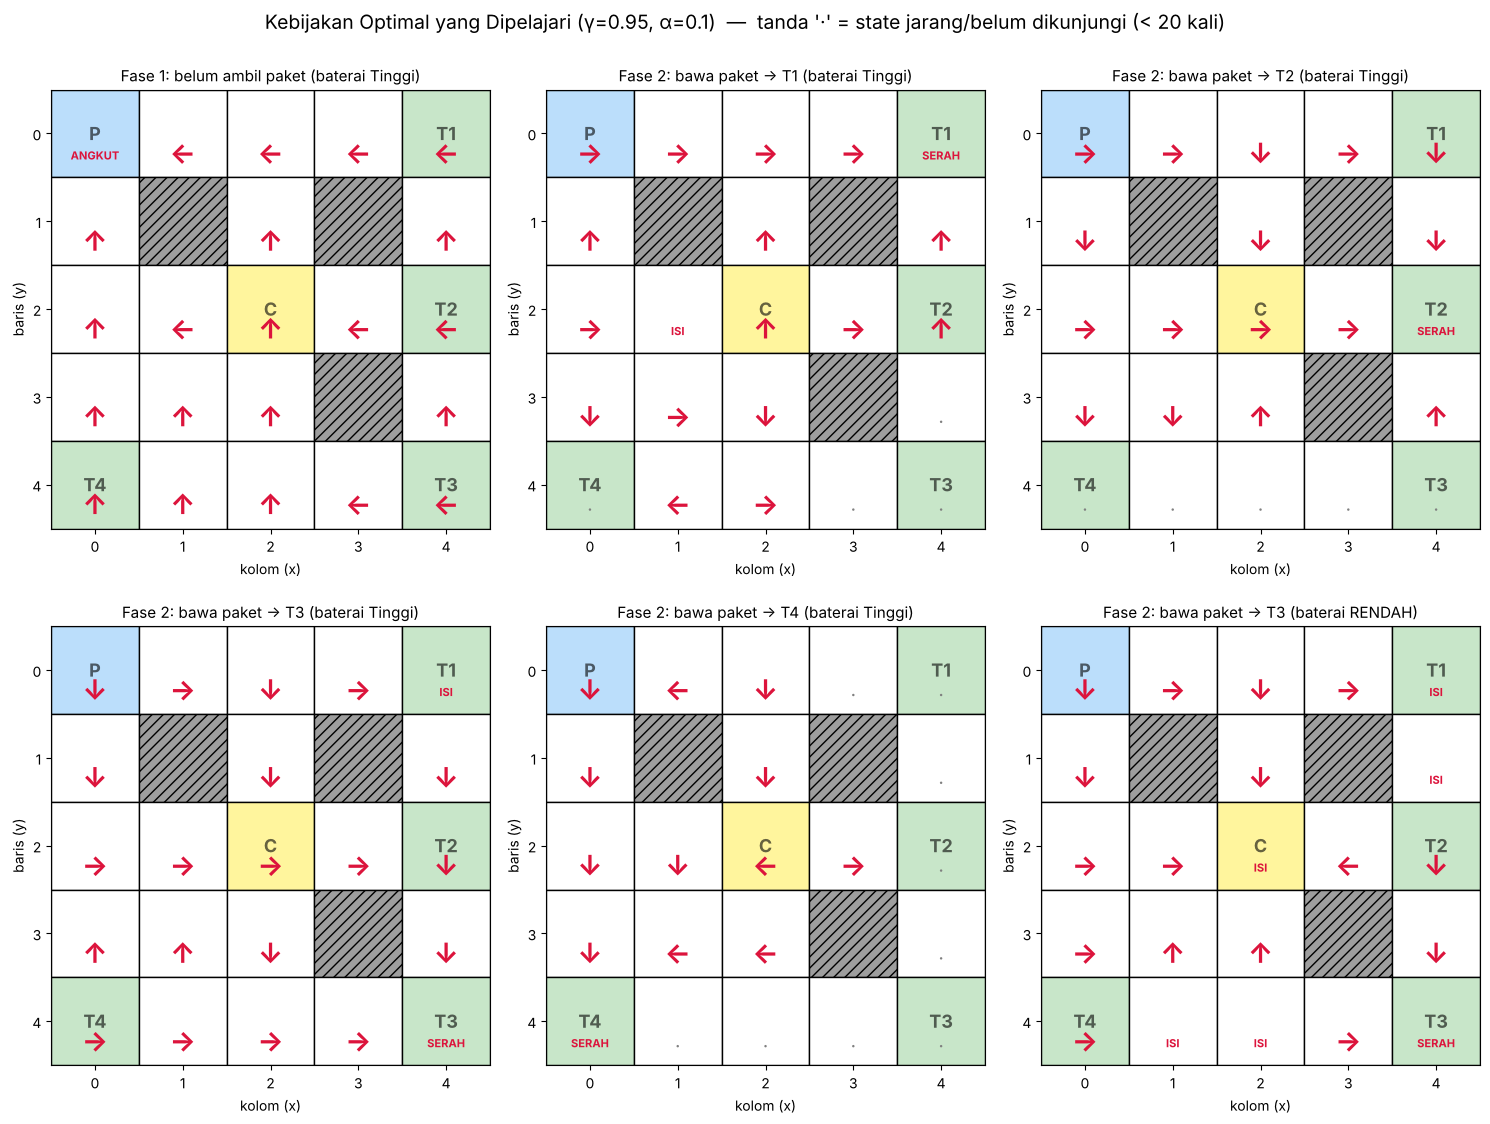

In [7]:
ARROWS = {0: "↑", 1: "↓", 2: "←", 3: "→"}
MIN_VISITS = 20      # state dengan kunjungan < 20 dianggap belum cukup dipelajari

def draw_policy(ax, Q, visits, carrying, dest, battery, title):
    """Gambar aksi optimal argmax_a Q(s,a) untuk setiap sel pada konteks (status paket, tujuan, baterai) tertentu."""
    e = CourierEnv()
    draw_map(ax, title)
    for (x, y) in e.free_cells:
        s = e.encode((x, y, dest, carrying, battery))
        if visits[s] < MIN_VISITS or np.allclose(Q[s], Q[s][0]):
            ax.text(x, y + .28, "·", ha="center", va="center", fontsize=14, color="gray")   # belum pernah dipelajari
            continue
        a = int(np.argmax(Q[s]))
        if a in ARROWS:
            ax.text(x, y + .22, ARROWS[a], ha="center", va="center", fontsize=20, color="crimson", fontweight="bold")
        else:
            word = ("ANGKUT" if carrying == 0 else "SERAH") if a == 4 else "ISI"
            ax.text(x, y + .25, word, ha="center", va="center", fontsize=8, color="crimson", fontweight="bold")

def plot_policies(Q, visits, suptitle):
    contexts = [
        (0, 0, 2, "Fase 1: belum ambil paket (baterai Tinggi)"),
        (1, 0, 2, "Fase 2: bawa paket → T1 (baterai Tinggi)"),
        (1, 1, 2, "Fase 2: bawa paket → T2 (baterai Tinggi)"),
        (1, 2, 2, "Fase 2: bawa paket → T3 (baterai Tinggi)"),
        (1, 3, 2, "Fase 2: bawa paket → T4 (baterai Tinggi)"),
        (1, 2, 0, "Fase 2: bawa paket → T3 (baterai RENDAH)"),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(15, 11))
    for ax, (carry, dest, batt, title) in zip(axes.ravel(), contexts):
        draw_policy(ax, Q, visits, carry, dest, batt, title)
    fig.suptitle(suptitle, fontsize=14, y=1.01)
    plt.tight_layout(h_pad=3); plt.show()

plot_policies(Q_base, base["visits"], "Kebijakan Optimal yang Dipelajari (γ=0.95, α=0.1)  —  tanda '·' = state jarang/belum dikunjungi (< 20 kali)")

In [8]:
from collections import deque

def shortest_dist(goal):
    """Jarak terpendek (BFS) dari setiap sel bebas ke `goal`, dengan memperhitungkan penghalang."""
    dist, q = {goal: 0}, deque([goal])
    while q:
        x, y = q.popleft()
        for dx, dy in CourierEnv.MOVES.values():
            n = (x + dx, y + dy)
            if 0 <= n[0] < 5 and 0 <= n[1] < 5 and n not in CourierEnv.WALLS and n not in dist:
                dist[n] = dist[(x, y)] + 1; q.append(n)
    return dist

def policy_quality(Q, visits, battery=2):
    """Persentase state (yang cukup dikunjungi) di mana aksi greedy memang mendekatkan agen ke targetnya
    (P pada fase 1, titik tujuan pada fase 2) atau melakukan Angkut/Serahkan tepat di targetnya."""
    e = CourierEnv(); hasil = {}
    for carry, nama in [(0, "Fase 1 (menuju P)"), (1, "Fase 2 (menuju tujuan)")]:
        benar = total = 0
        for d in range(4):
            goal = e.PICKUP if carry == 0 else e.DESTS[d]
            dist = shortest_dist(goal)
            if carry == 0 and d > 0:
                continue                      # tujuan tidak memengaruhi fase 1 -> cukup periksa satu tujuan
            for (x, y) in e.free_cells:
                s = e.encode((x, y, d, carry, battery))
                if visits[s] < MIN_VISITS:
                    continue
                a = int(np.argmax(Q[s])); total += 1
                if (x, y) == goal:
                    benar += (a == 4)
                elif a < 4:
                    dx, dy = e.MOVES[a]; n = (x + dx, y + dy)
                    benar += (n in dist and dist[n] < dist[(x, y)])
        hasil[nama] = (benar, total, benar / total if total else np.nan)
    return pd.DataFrame(hasil, index=["aksi tepat", "jumlah state", "persentase"]).T

policy_quality(Q_base, base["visits"])

,aksi tepat,jumlah state,persentase
Fase 1 (menuju P),22.0,22.0,1.000000
Fase 2 (menuju tujuan),60.0,70.0,0.857143


In [9]:
# Isi Q-Table untuk beberapa state penting
cols = [f"Q({n})" for n in CourierEnv.ACTION_NAMES]
def show_q(state, nama):
    s = env.encode(state)
    row = pd.Series(Q_base[s], index=cols, name=f"{nama} {state}")
    return row

contoh = pd.DataFrame([
    show_q((0, 0, 1, 0, 2), "Di P, belum ambil, tujuan T2, baterai Tinggi"),
    show_q((0, 1, 1, 0, 2), "Di bawah P, belum ambil, tujuan T2, baterai Tinggi"),
    show_q((3, 2, 1, 1, 2), "Di sebelah C, bawa paket, tujuan T2, baterai Tinggi"),
    show_q((4, 2, 1, 1, 2), "Di T2, bawa paket, tujuan T2, baterai Tinggi"),
    show_q((4, 1, 1, 1, 2), "Di atas T2, bawa paket, tujuan T2, baterai Tinggi"),
    show_q((2, 2, 2, 1, 0), "Di C, bawa paket, tujuan T3, baterai RENDAH"),
]).round(2)
contoh

,Q(Atas),Q(Bawah),Q(Kiri),Q(Kanan),Q(Angkut/Serahkan),Q(Isi daya)
"Di P, belum ambil, tujuan T2, baterai Tinggi (0, 0, 1, 0, 2)",10.53,9.44,10.47,9.08,17.05,12.53
"Di bawah P, belum ambil, tujuan T2, baterai Tinggi (0, 1, 1, 0, 2)",14.71,3.90,4.14,6.82,0.65,4.80
"Di sebelah C, bawa paket, tujuan T2, baterai Tinggi (3, 2, 1, 1, 2)",19.70,19.64,21.13,26.55,13.89,20.87
"Di T2, bawa paket, tujuan T2, baterai Tinggi (4, 2, 1, 1, 2)",18.67,15.50,23.20,21.22,29.00,23.78
"Di atas T2, bawa paket, tujuan T2, baterai Tinggi (4, 1, 1, 1, 2)",-0.10,25.70,-0.40,-0.33,-2.09,-0.30
"Di C, bawa paket, tujuan T3, baterai RENDAH (2, 2, 2, 1, 0)",-3.12,0.28,-4.03,-11.35,4.51,18.57


In [10]:
def evaluate_policy(Q, n_episodes=1000, seed=123, max_steps=100):
    """Jalankan kebijakan greedy murni (epsilon = 0) pada lingkungan stokastik."""
    env_e = CourierEnv(seed=seed)
    rng = np.random.default_rng(seed)
    rewards, steps_ok, outcomes = [], [], {"terantar": 0, "baterai habis": 0, "habis waktu (100 langkah)": 0}
    for _ in range(n_episodes):
        state, total = env_e.reset(), 0.0
        for t in range(max_steps):
            a = greedy_action(Q[env_e.encode(state)], rng)
            state, r, done = env_e.step(state, a)
            total += r
            if done:
                if r > 0:
                    outcomes["terantar"] += 1; steps_ok.append(t + 1)
                else:
                    outcomes["baterai habis"] += 1
                break
        else:
            outcomes["habis waktu (100 langkah)"] += 1
        rewards.append(total)
    return dict(reward_mean=np.mean(rewards), reward_std=np.std(rewards),
                success=outcomes["terantar"] / n_episodes,
                battery_dead=outcomes["baterai habis"] / n_episodes,
                timeout=outcomes["habis waktu (100 langkah)"] / n_episodes,
                steps_mean=np.mean(steps_ok) if steps_ok else np.nan)

ev_base = evaluate_policy(Q_base)
pd.DataFrame([ev_base], index=["Kebijakan greedy (γ=0.95, α=0.1)"]).round(3)

,reward_mean,reward_std,success,battery_dead,timeout,steps_mean
"Kebijakan greedy (γ=0.95, α=0.1)",12.873,31.963,0.879,0.117,0.004,14.258


In [11]:
# Contoh satu episode dengan kebijakan hasil pelatihan (greedy)
def run_trace(Q, start, seed=7):
    env_t = CourierEnv(seed=seed)
    rng = np.random.default_rng(seed)
    state, total, rows = start, 0.0, []
    for t in range(1, 101):
        a = greedy_action(Q[env_t.encode(state)], rng)
        new_state, r, done = env_t.step(state, a)
        total += r
        rows.append(dict(langkah=t, state=state, aksi=CourierEnv.ACTION_NAMES[a], reward=r, state_baru=new_state))
        state = new_state
        if done:
            break
    return pd.DataFrame(rows), total

# Mulai dari (4,4) = T3, tujuan T1, belum ambil paket, baterai Tinggi (rute jauh)
trace_df, total_r = run_trace(Q_base, start=(4, 4, 0, 0, 2))
print("Total reward episode contoh:", total_r, "| jumlah langkah:", len(trace_df))
trace_df

Total reward episode contoh: 21.0 | jumlah langkah: 14


,langkah,state,aksi,reward,state_baru
0,1,"(4, 4, 0, 0, 2)",Kiri,-1.0,"(3, 4, 0, 0, 2)"
1,2,"(3, 4, 0, 0, 2)",Kiri,-1.0,"(2, 4, 0, 0, 2)"
2,3,"(2, 4, 0, 0, 2)",Atas,-1.0,"(2, 3, 0, 0, 2)"
3,4,"(2, 3, 0, 0, 2)",Atas,-1.0,"(2, 2, 0, 0, 2)"
4,5,"(2, 2, 0, 0, 2)",Atas,-1.0,"(2, 1, 0, 0, 2)"
5,6,"(2, 1, 0, 0, 2)",Atas,-1.0,"(2, 0, 0, 0, 2)"
6,7,"(2, 0, 0, 0, 2)",Kiri,-1.0,"(1, 0, 0, 0, 1)"
7,8,"(1, 0, 0, 0, 1)",Kiri,-1.0,"(0, 0, 0, 0, 1)"
8,9,"(0, 0, 0, 0, 1)",Angkut/Serahkan,4.0,"(0, 0, 0, 1, 1)"
9,10,"(0, 0, 0, 1, 1)",Kanan,-1.0,"(1, 0, 0, 1, 1)"


### Interpretasi Kebijakan

**Alur berpikir agen.** Kebijakan terbagi menjadi dua fase:

1. **Fase 1 (belum membawa paket):** semua panah mengarah ke **P** di pojok kiri atas dan agen memilih *Angkut* tepat di P. Dari pemeriksaan jarak terpendek (BFS) pada sel yang cukup dikunjungi, **22 dari 22 state (100 %)** mengambil langkah yang tepat.
2. **Fase 2 (membawa paket):** panah berubah menuju titik tujuan yang diminta (T1–T4) dan agen memilih *Serahkan* ketika sampai. Sebagian besar sel mengikuti rute terpendek dan menghindari penghalang; **60 dari 70 state (≈ 86 %)** mengambil langkah yang mendekatkan agen ke tujuan.

**Apakah logis dan efisien?** Pada jalur yang sering dilalui, ya. Pada contoh episode (start di T3, tujuan T1) agen menuju P, mengambil paket, lalu mengantar dalam 14 langkah dengan total reward +21. Pada evaluasi greedy 1.000 episode, tingkat keberhasilan sekitar **88 %** dengan rata-rata ± **14 langkah** per pengantaran yang berhasil.

**Kelemahan yang ditemukan.**
- Sekitar 12 % episode gagal karena **baterai habis**. Dengan 3 tingkat baterai dan peluang turun 0,2 per gerakan, start yang jauh dari rute sering berisiko. Q-Learning belum selalu belajar mampir ke C pada saat yang tepat.
- Beberapa sel pada state yang jarang dikunjungi (terutama kombinasi tujuan–baterai yang jarang muncul) masih memiliki panah yang tidak optimal. Ini wajar karena α kecil memerlukan banyak kunjungan per state.
- Pada baterai **Rendah** di beberapa sel jauh dari C, agen kadang memilih *Isi daya* di luar stasiun (−2, tidak berisiko). Aksi ini lebih murah daripada risiko baterai habis (−50), tetapi hanya menunda masalah. Ini menunjukkan celah desain reward; perbaikannya, misalnya penalti isi daya di luar C diperbesar atau ditambah penalti waktu.


## Langkah 5 — Eksperimen Hiperparameter

- **Hiperparameter yang diubah:** hanya **γ (discount factor)**.
- **Model 1 (default/tinggi):** γ = 0,95. **Model 2 (ekstrem/rendah):** γ = 0,1.
- Semua pengaturan lain identik (α = 0,1, ε, decay, jumlah episode, seed).


In [12]:
# Eksperimen: hanya γ yang diubah. Semua yang lain (α, ε, seed, jumlah episode) identik.
GAMMA_HIGH, GAMMA_LOW = 0.95, 0.1

exp_high = base                                   # γ = 0.95 (default) -> sudah dilatih di atas
exp_low  = train_q_learning(alpha=0.1, gamma=GAMMA_LOW, episodes=EPISODES,
                            eps_start=1.0, eps_min=0.05, decay_rate=0.001, verbose=True)

ev_high = evaluate_policy(exp_high["Q"])
ev_low  = evaluate_policy(exp_low["Q"])
tabel = pd.DataFrame([ev_high, ev_low], index=[f"γ = {GAMMA_HIGH} (default/tinggi)", f"γ = {GAMMA_LOW} (sangat rendah)"]).round(3)
tabel.columns = ["reward rata-rata", "std reward", "tingkat sukses", "baterai habis", "habis waktu", "langkah rata-rata (sukses)"]
tabel

Episode  2000 | eps=0.179 | rata2 reward (100 terakhir)=-137.53 | sukses (100 terakhir)=0.09
Episode  4000 | eps=0.067 | rata2 reward (100 terakhir)=-136.36 | sukses (100 terakhir)=0.22
Episode  6000 | eps=0.052 | rata2 reward (100 terakhir)=-104.17 | sukses (100 terakhir)=0.28
Episode  8000 | eps=0.050 | rata2 reward (100 terakhir)=-106.31 | sukses (100 terakhir)=0.29
Episode 10000 | eps=0.050 | rata2 reward (100 terakhir)=-108.89 | sukses (100 terakhir)=0.32
Episode 12000 | eps=0.050 | rata2 reward (100 terakhir)=-100.87 | sukses (100 terakhir)=0.33
Episode 14000 | eps=0.050 | rata2 reward (100 terakhir)=-121.67 | sukses (100 terakhir)=0.22
Episode 16000 | eps=0.050 | rata2 reward (100 terakhir)= -67.32 | sukses (100 terakhir)=0.48
Episode 18000 | eps=0.050 | rata2 reward (100 terakhir)= -96.40 | sukses (100 terakhir)=0.32
Episode 20000 | eps=0.050 | rata2 reward (100 terakhir)= -81.89 | sukses (100 terakhir)=0.43


,reward rata-rata,std reward,tingkat sukses,baterai habis,habis waktu,langkah rata-rata (sukses)
γ = 0.95 (default/tinggi),12.873,31.963,0.879,0.117,0.004,14.258
γ = 0.1 (sangat rendah),-77.185,96.105,0.247,0.000,0.753,10.105


Rata-rata reward 1000 episode terakhir  : γ=0.95 -> 8.62  |  γ=0.1 -> -97.45
Sukses 1000 episode terakhir            : γ=0.95 -> 85.70%  |  γ=0.1 -> 32.40%


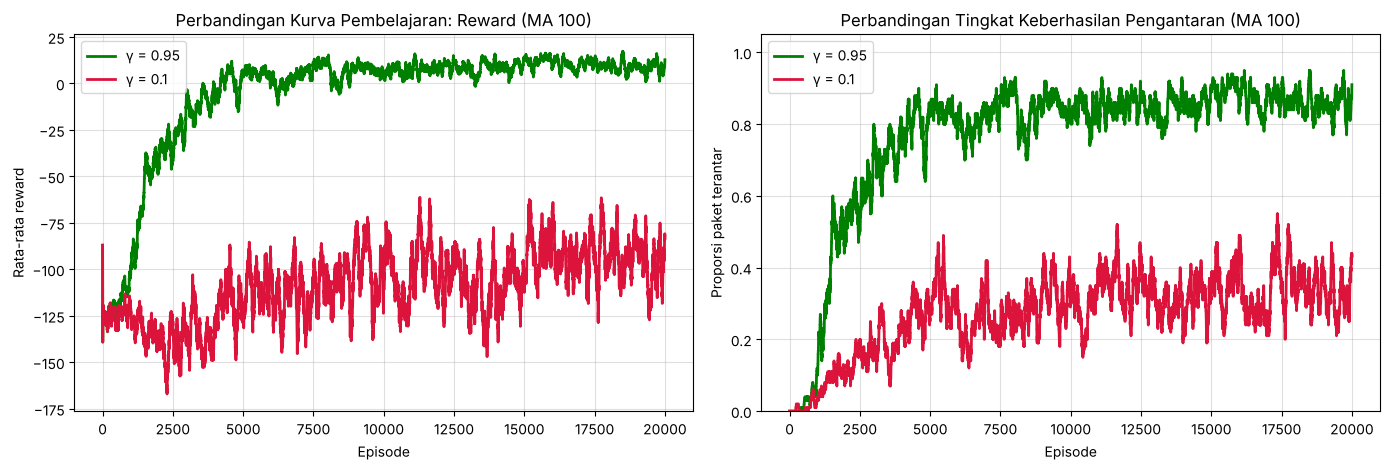

In [13]:
ma_h = moving_average(exp_high["rewards"], WINDOW)
ma_l = moving_average(exp_low["rewards"], WINDOW)
ms_h = moving_average(exp_high["success"], WINDOW)
ms_l = moving_average(exp_low["success"], WINDOW)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(ma_h, color="green", lw=2, label=f"γ = {GAMMA_HIGH}")
axes[0].plot(ma_l, color="crimson", lw=2, label=f"γ = {GAMMA_LOW}")
axes[0].set_title(f"Perbandingan Kurva Pembelajaran: Reward (MA {WINDOW})")
axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Rata-rata reward"); axes[0].legend(); axes[0].grid(True, alpha=.4)

axes[1].plot(ms_h, color="green", lw=2, label=f"γ = {GAMMA_HIGH}")
axes[1].plot(ms_l, color="crimson", lw=2, label=f"γ = {GAMMA_LOW}")
axes[1].set_title(f"Perbandingan Tingkat Keberhasilan Pengantaran (MA {WINDOW})")
axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Proporsi paket terantar"); axes[1].set_ylim(0, 1.05)
axes[1].legend(); axes[1].grid(True, alpha=.4)
plt.tight_layout(); plt.show()

print("Rata-rata reward 1000 episode terakhir  :", f"γ=0.95 -> {exp_high['rewards'][-1000:].mean():.2f}  |  γ=0.1 -> {exp_low['rewards'][-1000:].mean():.2f}")
print("Sukses 1000 episode terakhir            :", f"γ=0.95 -> {exp_high['success'][-1000:].mean():.2%}  |  γ=0.1 -> {exp_low['success'][-1000:].mean():.2%}")

max_a Q(s,a) untuk state bawa-paket, tujuan T3, baterai Tinggi:


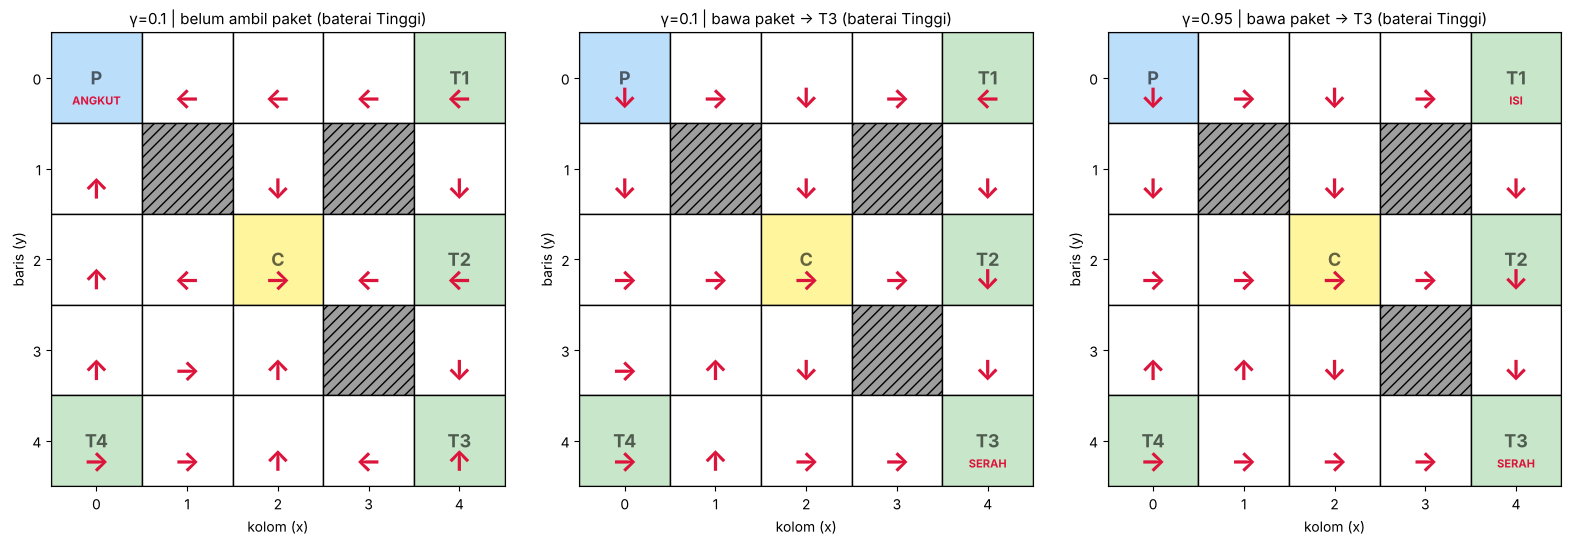

,γ=0.95,γ=0.1
"1 langkah dari T3 (4,3)",26.550,1.900
"3 langkah dari T3 (4,1)",14.289,-0.958
"jauh dari T3 (0,2)",14.778,-1.108


In [14]:
# Bandingkan kebijakan hasil γ rendah (agen "miopik")
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
draw_policy(axes[0], exp_low["Q"], exp_low["visits"], 0, 0, 2, "γ=0.1 | belum ambil paket (baterai Tinggi)")
draw_policy(axes[1], exp_low["Q"], exp_low["visits"], 1, 2, 2, "γ=0.1 | bawa paket → T3 (baterai Tinggi)")
draw_policy(axes[2], exp_high["Q"], exp_high["visits"], 1, 2, 2, "γ=0.95 | bawa paket → T3 (baterai Tinggi)")
plt.tight_layout(); plt.show()

# Nilai Q maksimum di titik awal/menjauh dari tujuan: seberapa jauh agen "melihat" reward akhir?
def vmax(res, state): return res["Q"][env.encode(state)].max()
cek = pd.DataFrame({
    "γ=0.95": [vmax(exp_high, (4, 3, 2, 1, 2)), vmax(exp_high, (4, 1, 2, 1, 2)), vmax(exp_high, (0, 2, 2, 1, 2))],
    "γ=0.1" : [vmax(exp_low,  (4, 3, 2, 1, 2)), vmax(exp_low,  (4, 1, 2, 1, 2)), vmax(exp_low,  (0, 2, 2, 1, 2))],
}, index=["1 langkah dari T3 (4,3)", "3 langkah dari T3 (4,1)", "jauh dari T3 (0,2)"]).round(3)
print("max_a Q(s,a) untuk state bawa-paket, tujuan T3, baterai Tinggi:")
cek

### Analisis Hasil Eksperimen γ

| | γ = 0,95 | γ = 0,1 |
|---|---|---|
| Tingkat sukses (greedy, 1.000 episode) | **87,9 %** | 24,7 % |
| Reward rata-rata | **+12,9** | −77,2 |
| Baterai habis | 11,7 % | 0 % |
| Habis waktu (100 langkah) | 0,4 % | **75,3 %** |

**1. Kurva pembelajaran.** Dengan γ = 0,95, reward naik dari sekitar −126 ke plateau positif. Dengan γ = 0,1 reward tetap sangat negatif (±−100) dan tingkat sukses saat pelatihan hanya sekitar 20–50 %. Agen tidak pernah menyelesaikan tugas dengan konsisten.

**2. Mengapa agen "miopik".** Reward +29 saat paket terantar hanya sampai ke state sebelumnya dikalikan γ. Tabel di atas menunjukkan max Q satu langkah dari T3 hanya **1,9** (= −1 + 0,1 × 29), tiga langkah dari tujuan **−0,96**, dan di sel yang jauh **−1,1**. Artinya sinyal +29 praktis **menghilang setelah 2–3 langkah**, sehingga agen tidak punya alasan memilih rute menuju tujuan dari jauh. Dengan γ = 0,95, nilai Q di sel yang sama tetap besar (14–27).

**3. Perilaku yang muncul.** Pada contoh episode γ = 0,1, agen berputar antara C `(2,2)` dan sel di sebelahnya sambil terus mengisi daya. Setiap kali baterai turun, agen mendapat reward lokal +1 (+2 −1). Karena yang dilihat hanya reward instan, agen "memanen" hadiah kecil ini daripada mengejar +29 yang jauh. Hal ini menjelaskan mengapa baterai tidak pernah habis (0 %) tetapi 75 % episode berakhir *timeout*. Pengantaran yang berhasil hanya terjadi bila start sudah dekat rute (rata-rata 10,1 langkah, lebih pendek karena hanya kasus mudah yang berhasil).

**Kesimpulan eksperimen:** untuk tugas multi-langkah dengan reward utama di akhir (pickup → antar), γ harus cukup tinggi agar reward akhir "terlihat" dari state awal. Catatan: percobaan ini memakai satu seed; untuk kesimpulan yang lebih kuat, ulangi dengan beberapa seed dan rata-ratakan.


## Kesimpulan

1. Lingkungan kurir 5×5 dengan baterai (600 state × 6 aksi) cukup kecil untuk Q-Learning tabular. Agen belajar mengantar paket dengan tingkat sukses greedy ≈ **88 %** dan ± 14 langkah per pengantaran.
2. Konvergensi reward tercapai sekitar episode ke-8.600, setelah ε sudah berada di dasar (≈ 0,05). Peluruhan ε yang stabil menjadi kunci transisi dari eksplorasi ke eksploitasi.
3. Kebijakan yang dipelajari logis: fase 1 menuju P, fase 2 menuju tujuan yang diminta. Kelemahannya adalah manajemen baterai yang belum optimal dan beberapa panah keliru pada state yang jarang dikunjungi.
4. Eksperimen γ menunjukkan bahwa γ sangat rendah membuat agen miopik (sukses turun dari ≈ 88 % ke ≈ 25 %), karena reward akhir tidak lagi berpengaruh pada keputusan di state yang jauh.
5. **Pengembangan:** tambah episode atau α yang dijadwalkan, perbaiki reward (penalti isi daya di luar C), dan uji dengan beberapa seed.
